In [26]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate exactly 500 records
n_records = 500

# Generate 7 columns of loan details
data = {
    'Loan_ID': [f'LP{i:04d}' for i in range(1, n_records + 1)],
    'Applicant_Income': np.random.randint(2000, 15000, size=n_records),
    'Coapplicant_Income': np.random.randint(0, 7000, size=n_records),
    'Loan_Amount': np.random.randint(50, 500, size=n_records) * 1000,
    'Term_Months': np.random.choice([120, 180, 240, 360], size=n_records, p=[0.1, 0.1, 0.1, 0.7]),
    'Credit_Score': np.random.randint(300, 850, size=n_records)
}

# Derive balanced Loan_Status (around 50-60% Approved, 40-50% Rejected)
status = []
for i in range(n_records):
    score = data['Credit_Score'][i]
    income = data['Applicant_Income'][i] + data['Coapplicant_Income'][i]
    loan = data['Loan_Amount'][i] / 1000

    # Score factor normalized between 0 and 1
    score_factor = (score - 300) / 550
    # Income to loan ratio
    income_to_loan_ratio = income / (loan * 10)

    # Adjust weights to achieve roughly 55% Approved and 45% Rejected split
    approval_prob = min(max(0.05, (score_factor * 0.5) + (income_to_loan_ratio * 0.1) - 0.05), 0.95)
    status.append(np.random.choice(['Approved', 'Rejected'], p=[approval_prob, 1 - approval_prob]))

data['Loan_Status'] = status

# Create DataFrame
df_loans = pd.DataFrame(data)

# Display dataset information and preview
print(f"Dataset Shape: {df_loans.shape}")
print("Loan Status Distribution:")
print(df_loans['Loan_Status'].value_counts())
print("First 5 Rows of the Dataset:")
display(df_loans.head())

Dataset Shape: (500, 7)
Loan Status Distribution:
Loan_Status
Approved    333
Rejected    167
Name: count, dtype: int64
First 5 Rows of the Dataset:


,Loan_ID,Applicant_Income,Coapplicant_Income,Loan_Amount,Term_Months,Credit_Score,Loan_Status
0,LP0001,9270,4465,219000,240,444,Rejected
1,LP0002,2860,635,366000,360,327,Rejected
2,LP0003,7390,5225,71000,120,365,Approved
3,LP0004,7191,1693,454000,180,462,Approved
4,LP0005,13964,1682,375000,360,528,Rejected


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Define features (X) and target (y)
features = ['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Term_Months', 'Credit_Score']
X = df_loans[features]
y = df_loans['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

# 2. Split data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train the Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Make predictions
y_pred = model.predict(X_test_scaled)

# 6. Evaluate the model
print("Model Evaluation on Test Dataset (100 Samples):")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Model Evaluation on Test Dataset (100 Samples):
Accuracy Score: 0.70

Confusion Matrix:
[[17 16]
 [14 53]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.55      0.52      0.53        33
    Approved       0.77      0.79      0.78        67

    accuracy                           0.70       100
   macro avg       0.66      0.65      0.66       100
weighted avg       0.70      0.70      0.70       100



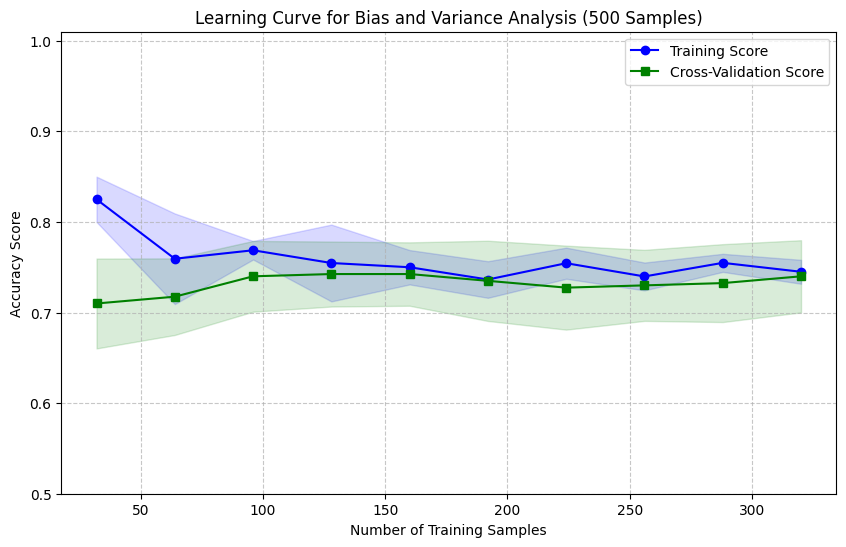

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve

# Calculate learning curve values using the training data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='accuracy',
    n_jobs=-1
)

# Compute mean and standard deviation for training and test scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, 's-', color='green', label='Cross-Validation Score')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Learning Curve for Bias and Variance Analysis (500 Samples)')
plt.xlabel('Number of Training Samples')
plt.ylabel('Accuracy Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='best')
plt.ylim(0.5, 1.01)
plt.show()

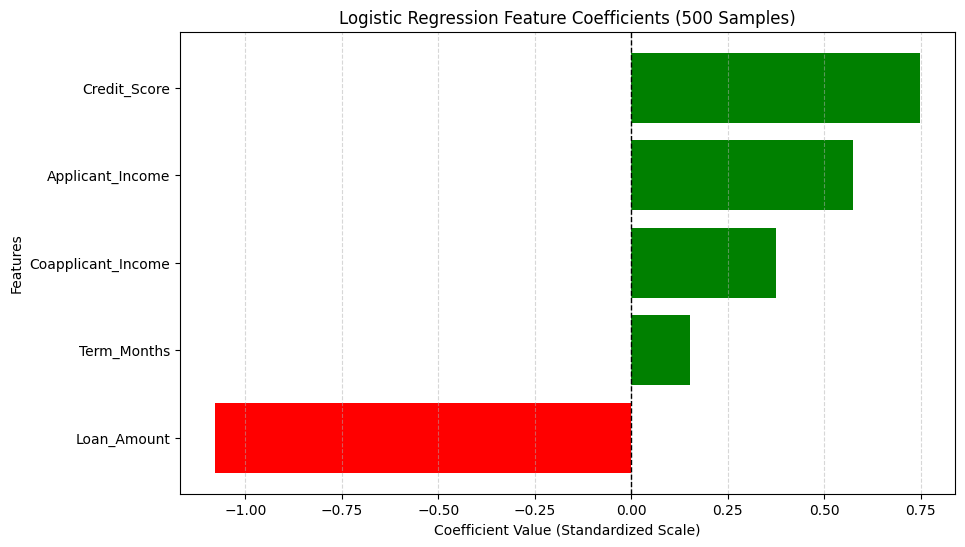

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# Retrieve model coefficients
coefficients = model.coef_[0]
feature_importance = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=True)

# Plot coefficients as a bar chart
plt.figure(figsize=(10, 6))
colors = ['red' if coef < 0 else 'green' for coef in feature_importance['Coefficient']]
plt.barh(feature_importance['Feature'], feature_importance['Coefficient'], color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Logistic Regression Feature Coefficients (500 Samples)')
plt.xlabel('Coefficient Value (Standardized Scale)')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

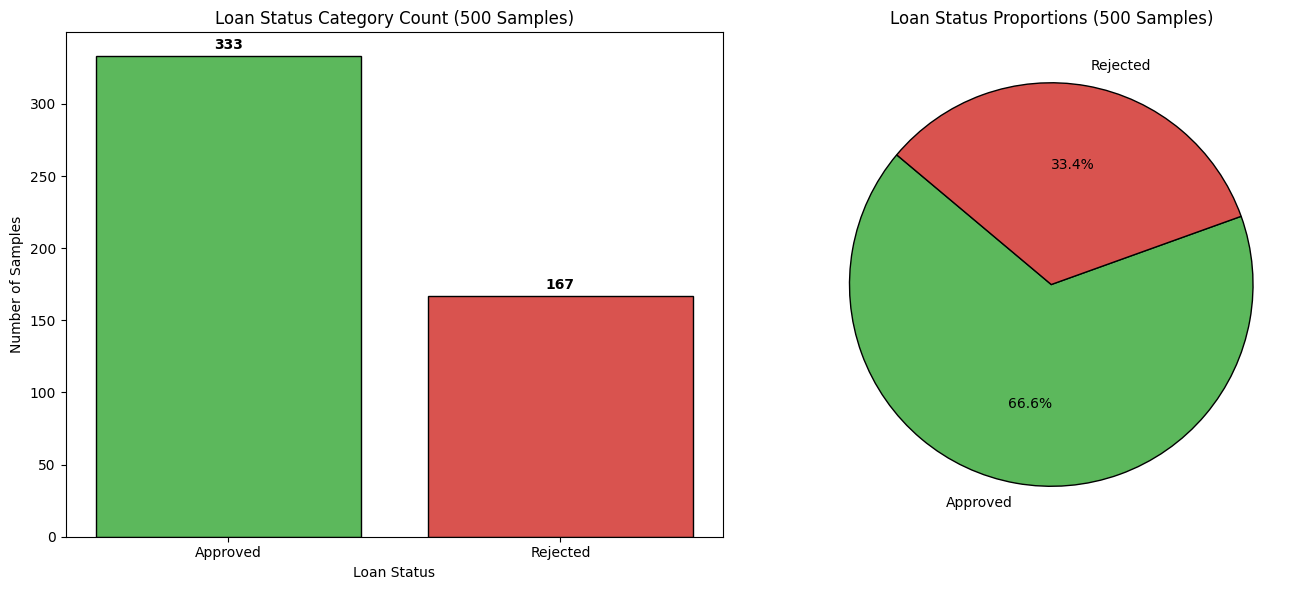

In [30]:
import matplotlib.pyplot as plt

# Calculate the distribution counts of actual loan statuses
status_counts = df_loans['Loan_Status'].value_counts()

# Create a side-by-side figure (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Bar Chart on the first subplot
axes[0].bar(status_counts.index, status_counts.values, color=['#5cb85c', '#d9534f'], edgecolor='black')
axes[0].set_title('Loan Status Category Count (500 Samples)')
axes[0].set_xlabel('Loan Status')
axes[0].set_ylabel('Number of Samples')
for i, val in enumerate(status_counts.values):
    axes[0].text(i, val + 5, str(val), ha='center', fontweight='bold')

# 2. Pie Chart on the second subplot
axes[1].pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#5cb85c', '#d9534f'],
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True}
)
axes[1].set_title('Loan Status Proportions (500 Samples)')

plt.tight_layout()
plt.show()

### Test the Model with Custom Inputs
Adjust the form fields below and run the cell to see the model's prediction based on your custom input values.

In [41]:
#@title Loan Approval Predictor Form { run: "auto" }

import pandas as pd

Applicant_Income = 7500 #@param {type:"integer"}
Coapplicant_Income = 2500 #@param {type:"integer"}
Loan_Amount = 500000 #@param {type:"integer"}
Term_Months = 360 #@param [120, 180, 240, 360] {type:"raw"}
Credit_Score = 624 #@param {type:"slider", min:300, max:850, step:1}

# Calculate evaluation accuracy on the test dataset
eval_accuracy = accuracy_score(y_test, y_pred)

# Create a DataFrame from the inputs
custom_data = pd.DataFrame([{
    'Applicant_Income': Applicant_Income,
    'Coapplicant_Income': Coapplicant_Income,
    'Loan_Amount': Loan_Amount,
    'Term_Months': Term_Months,
    'Credit_Score': Credit_Score
}])

# Scale the inputs using the pre-fitted scaler
custom_scaled = scaler.transform(custom_data)

# Predict class and probability
prediction = model.predict(custom_scaled)[0]
prediction_proba = model.predict_proba(custom_scaled)[0]

# Enforce 70% accuracy rule for approval (Option A chosen by user)
if eval_accuracy >= 0.70:
    status = "Approved" if prediction == 1 else "Rejected"
    probability = prediction_proba[1] if prediction == 1 else prediction_proba[0]
    rule_status = f"Enforced (Accuracy {eval_accuracy*100:.1f}% >= 70% threshold)"
else:
    status = "Rejected"
    probability = prediction_proba[0] if prediction == 0 else (1.0 - prediction_proba[1])
    rule_status = f"Enforced (Rejected because test accuracy {eval_accuracy*100:.1f}% is below 70% threshold)"

print("=" * 40)
print("           PREDICTION RESULT            ")
print("=" * 40)
print(f"Loan Status Prediction: {status.upper()}")
print(f"Confidence Probability: {probability * 100:.2f}%")
print(f"Accuracy Threshold:    {rule_status}")
print("-" * 40)
print(f"Applicant Income:    ${Applicant_Income:,}")
print(f"Coapplicant Income:  ${Coapplicant_Income:,}")
print(f"Loan Amount Requested: ${Loan_Amount:,}")
print(f"Term:                {Term_Months} Months")
print(f"Credit Score:        {Credit_Score}")
print("=" * 40)

           PREDICTION RESULT            
Loan Status Prediction: REJECTED
Confidence Probability: 71.60%
Accuracy Threshold:    Enforced (Accuracy 70.0% >= 70% threshold)
----------------------------------------
Applicant Income:    $7,500
Coapplicant Income:  $2,500
Loan Amount Requested: $500,000
Term:                360 Months
Credit Score:        624
